In [1]:
%matplotlib widget
from dataclasses import dataclass

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import polars as pl
import scipy.optimize as scio
from jax.tree_util import register_dataclass
from matplotlib import ticker

jax.config.update("jax_enable_x64", True) 
jax.config.update("jax_debug_nans", True)
cmap = 'jet'

data_uncoupled  = pl.read_parquet("data_complete/2026_9_23_18h19.parquet")

In [2]:
w01 = 97 * 2 * jnp.pi
Cp1 = 5.7781e-9
km21 = 0.35342
Q1 = 65.701
M1 = 0.1
ProtoCaracsRef1 = jnp.array([w01, Cp1, km21, Q1, M1])

w02 = 127.96 * 2 * jnp.pi
Cp2 = 3.7888e-9
km22 = 1.1055
Q2 = 66.846
M2 = 0.05
ProtoCaracsRef2 = jnp.array([w02, Cp2, km22, Q2, M2])

In [3]:
results_uncoupled = data_uncoupled.group_by(
    pl.col("f")
).agg(
    pl.col("pow1").max().alias("pow1max"),
    pl.col('Rload')
)

Ropt_uncoupled = []
for f in (results_uncoupled["f"]):
        p = results_uncoupled.filter(pl.col("f") == f)["pow1max"]
        d = data_uncoupled.filter((pl.col("f")==f) & (pl.col("pow1") == p))["Rload"]
        Ropt_uncoupled.append(d[0])


# Récupère les listes de fréquences et de résistances et jnp array

frequency_list = jnp.asarray(results_uncoupled['f'])
omega_list = frequency_list * 2 * jnp.pi
power1_exp = jnp.asarray(results_uncoupled['pow1max'])
resistance_list = jnp.asarray(data_uncoupled.select('Rload').unique()["Rload"])

In [4]:
# Fonction qui calcule la puissance


def system_signals(w, R, vect):
    """
    returns x1, x2, phi_x1, phi_x2, v1, v2, P1in, P2in
    position resonator 1, voltage resonator 1
    position resonator 2, voltage resonator 2
    computed by analytical analysis
    for the two couples linear resonators system
    """

    gamma = 0.15

    w0 = vect[0]
    Cp = vect[1]
    km2 = vect[2]
    Q = vect[3]
    M = vect[4]

    alpha = jnp.sqrt(km2 * M * w0**2 * Cp)
    a = -(w**2) + 1.0j * w * w0 / Q + w0**2
    b = alpha / M
    c = 1.0j * w * alpha
    d = 1.0j * w * Cp + 1 / R

    v = c * gamma / (b * c + d * a)

    P = jnp.abs(v) ** 2 / (2 * R)

    return w, R, P

In [9]:
# Calcul de la puissance en vmap sur omega et R

vpower = jax.vmap(
    system_signals,
    in_axes=(
        0,        # omega
        0,     # R
        None,     # vect
    ),
)



In [10]:
def error1_function(X0):
    caracs = X0 * ProtoCaracsRef1
    w, r, power_sim = vpower(omega_list, Ropt_uncoupled, caracs)
    return (power_sim - power1_exp).flatten()

# def error2_function(X0):
#     caracs = X0 * ProtoCaracsRef2
#     w, r, power_sim = power(caracs)
#     return (power_sim - power2_exp).flatten()

In [11]:
x01 = jnp.ones_like(ProtoCaracsRef1)
res1 = scio.least_squares(error1_function, x01)
xf1 = res1.x
ProtoCaracsOpt1 = xf1 * ProtoCaracsRef1

# x02 = jnp.ones_like(ProtoCaracsRef2)
# res2 = scio.least_squares(error2_function, x02)
# xf2 = res2.x
# ProtoCaracsOpt2 = xf2 * ProtoCaracsRef2


print(
    f"w01 = {ProtoCaracsOpt1[0] / (2 * jnp.pi)}, \nCp1 = {ProtoCaracsOpt1[1]}, \nkm21 = {ProtoCaracsOpt1[2]}, \nQ1 = {ProtoCaracsOpt1[3]}, \nM1 = {ProtoCaracsOpt1[4]}"
    )


# print(
#     "w02 = {}, \nCp2 = {}, \nkm22 = {}, \nQ2 = {}, \nM2 = {}".format(
#         ProtoCaracsOpt2[0] / (2 * jnp.pi), ProtoCaracsOpt2[1], ProtoCaracsOpt2[2], ProtoCaracsOpt2[3], ProtoCaracsOpt2[4]
#     )
# )

ValueError: vmap was requested to map its argument along axis 0, which implies that its rank should be at least 1, but is only 0 (its shape is ())

In [ ]:
w_grid, R_grid, power1_th = vpower(frequency_list, resistance_list, ProtoCaracsOpt1)
f_grid = w_grid / (2. * jnp.pi)

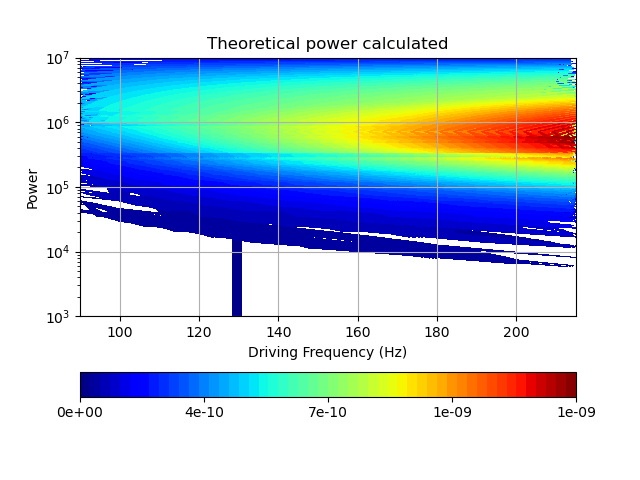

In [ ]:
plt.figure()
plt.contourf(frequency_list, resistance_list, power1_th, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Theoretical power calculated")
# plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [ ]:
fig = go.Figure(data=[
    go.Surface(x=f_grid, y=jnp.log10(R_grid), z=power1_exp*1.e6, opacity=0.5),
    go.Surface(x=f_grid, y=jnp.log10(R_grid), z=power1_th*1.e6, opacity = .5, showscale=False, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

TypeError: Input z must be 2D, not 1D

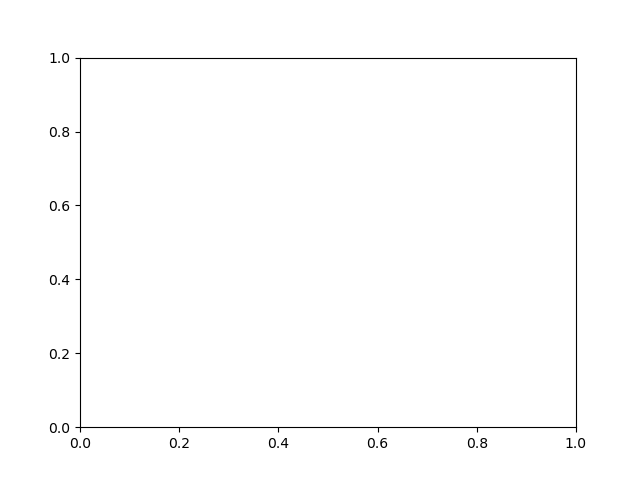

In [ ]:
plt.figure()
plt.contourf(frequency_list, resistance_list, power1_exp, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Experimental power")
#plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [ ]:
fig = go.Figure(data=[
    go.Surface(x=f_grid, y=jnp.log10(R_grid), z=(power1_th - power1_exp)*1.e6, opacity=0.5, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

/tmp/ipykernel_99023/196319669.py:14: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



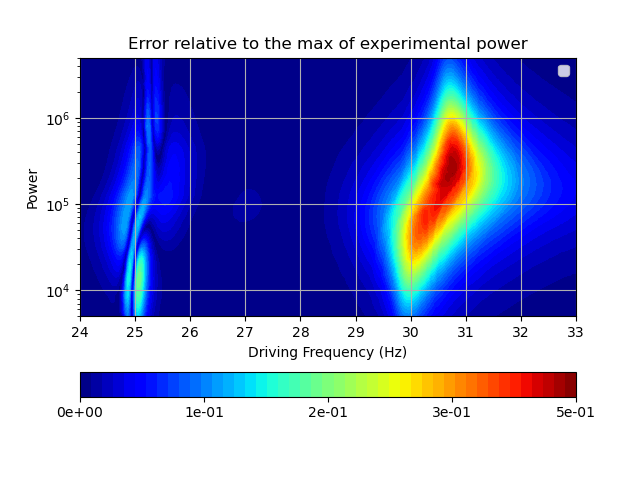

In [ ]:
plt.figure()
plt.contourf(
    frequency_list,
    resistance_list,
    abs(power1_exp - power1_th) / (power1_exp.max(axis=1).max(axis=0)),
    50,
    cmap=cmap,
)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Error relative to the max of experimental power")
plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

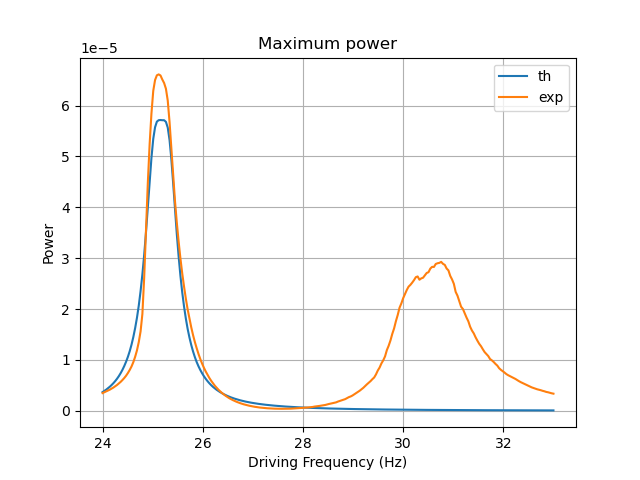

In [ ]:
plt.figure()
plt.plot(frequency_list, power1_th.max(axis=0), label="th")
plt.plot(frequency_list, power1_exp.max(axis=0), label="exp")
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Maximum power")
plt.legend()
plt.grid()
plt.show()

In [ ]:
w_grid, R_grid, power2_th = power(ProtoCaracsOpt2)
f_grid = w_grid / (2. * jnp.pi)

/tmp/ipykernel_99023/3445507096.py:8: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



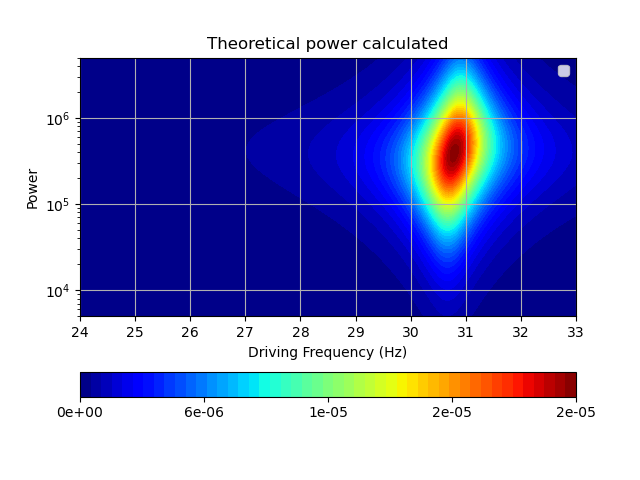

In [ ]:
plt.figure()
plt.contourf(f_grid, R_grid, power2_th, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Theoretical power calculated")
plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [ ]:
fig = go.Figure(data=[
    go.Surface(x=f_grid, y=jnp.log10(R_grid), z=power2_exp*1.e6, opacity=0.5),
    # go.Surface(x=f_grid, y=jnp.log10(R_grid), z=power2_th*1.e6, opacity = .5, showscale=False, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

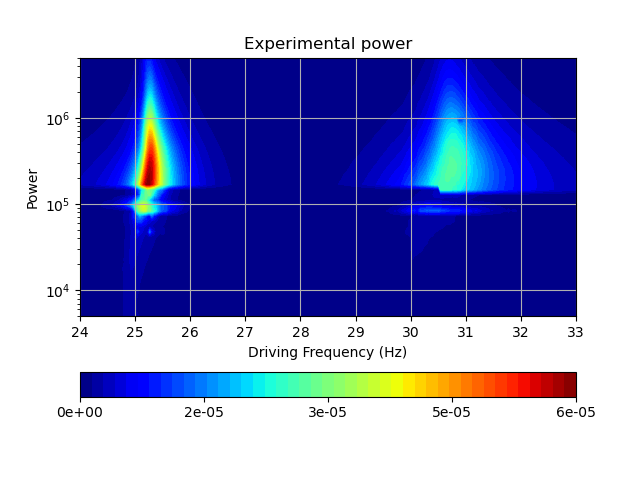

In [ ]:
plt.figure()
plt.contourf(frequency_list, resistance_list, power2_exp, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Experimental power")
#plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [ ]:
fig = go.Figure(data=[
    go.Surface(x=f_grid, y=jnp.log10(R_grid), z=(power2_th - power2_exp)*1.e6, opacity=0.5, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

/tmp/ipykernel_99023/2033670759.py:14: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



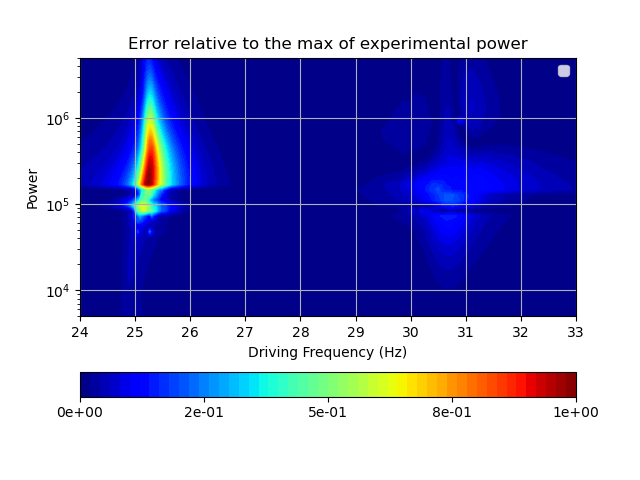

In [ ]:
plt.figure()
plt.contourf(
    frequency_list,
    resistance_list,
    abs(power2_exp - power2_th) / (power2_exp.max(axis=1).max(axis=0)),
    50,
    cmap=cmap,
)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Error relative to the max of experimental power")
plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

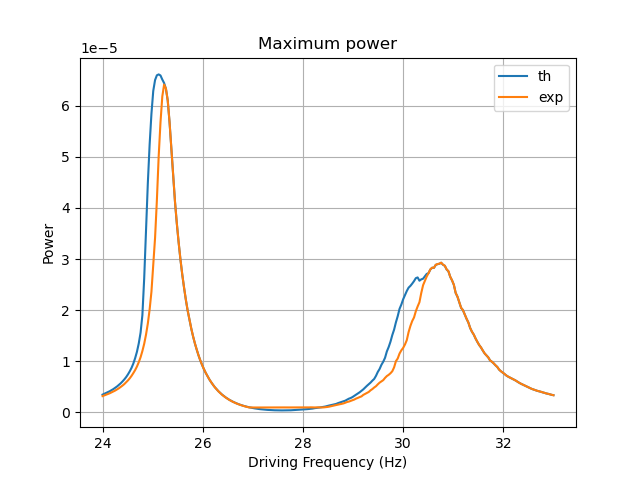

In [ ]:
plt.figure()
plt.plot(frequency_list, power1_exp.max(axis=0), label="th")
plt.plot(frequency_list, power2_exp.max(axis=0), label="exp")
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Maximum power")
plt.legend()
plt.grid()
plt.show()